In [1]:
%pip install -r ../requirements.txt


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
ruta_csv = "../data/raw/hour.csv"
df = pd.read_csv(ruta_csv)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [4]:
df.shape

(17379, 17)

In [5]:
df.head(5)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


# 3.Análisis de datos (EDA) + preprocesado


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


# 3.1 Limpieza inicial

In [7]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [8]:

df.dropna(inplace=True)

In [9]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [10]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


In [11]:
cortes = df['cnt'].describe()
print(cortes[['25%', '50%', '75%']])

25%     40.0
50%    142.0
75%    281.0
Name: cnt, dtype: float64


# 3.2 Visualización

<Axes: xlabel='cnt', ylabel='Count'>

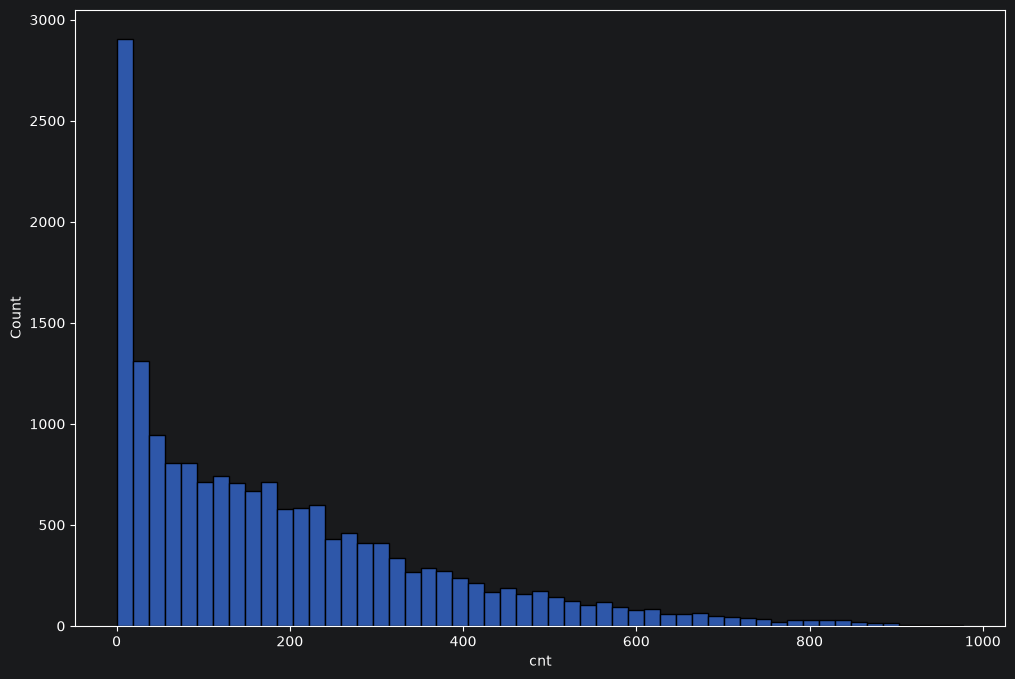

In [12]:
plt.figure(figsize=(12,8))
sns.histplot(df['cnt']) 

C:\Users\rober\AppData\Local\Temp\ipykernel_11208\1067368065.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['cnt'])


<Axes: xlabel='cnt', ylabel='Density'>

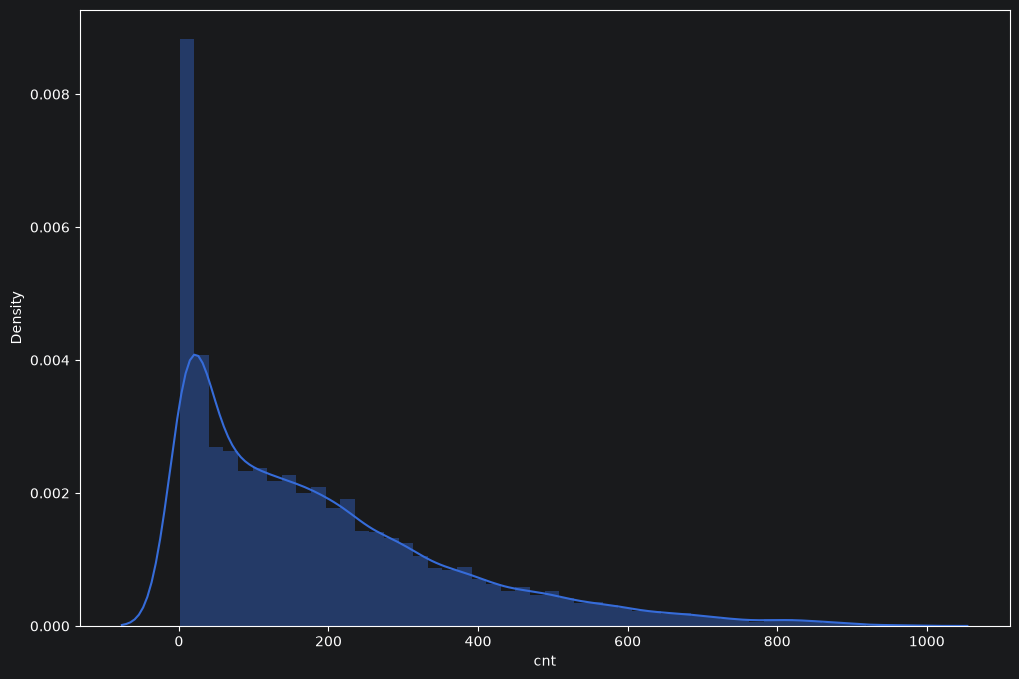

In [13]:
plt.figure(figsize=(12,8))
sns.distplot(df['cnt'])

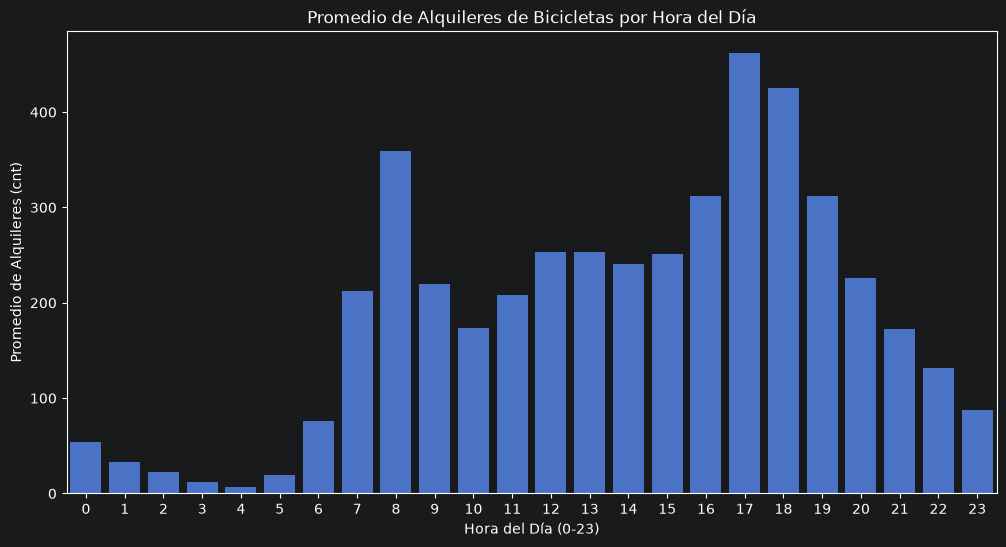

In [14]:
plt.figure(figsize=(12,6))
sns.barplot(data=df, x='hr', y='cnt', estimator=np.mean,errorbar=None)
plt.title("Promedio de Alquileres de Bicicletas por Hora del Día")
plt.xlabel("Hora del Día (0-23)")
plt.ylabel("Promedio de Alquileres (cnt)")
plt.show()


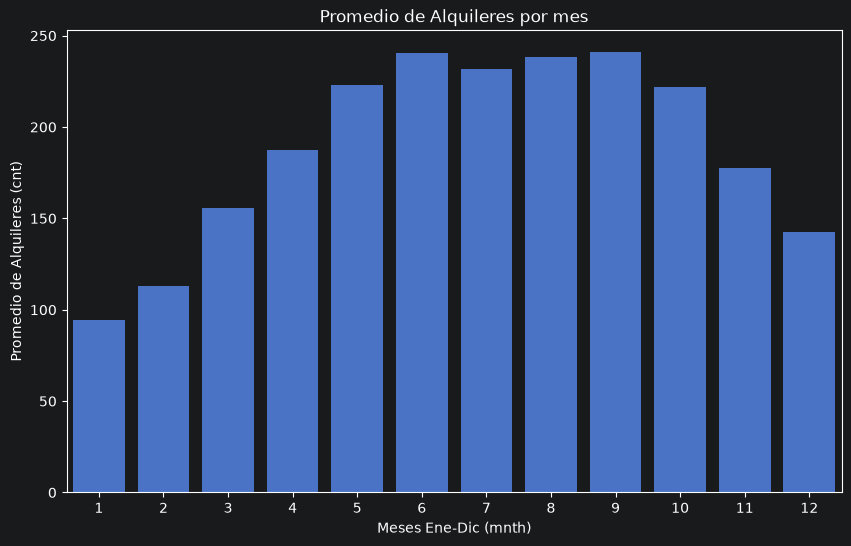

In [15]:
plt.figure(figsize=(10,6))
sns.barplot(data=df, x='mnth', y='cnt', estimator=np.mean, errorbar=None)
plt.title("Promedio de Alquileres por mes")
plt.xlabel("Meses Ene-Dic (mnth)")
plt.ylabel("Promedio de Alquileres (cnt)")
plt.show()


Text(0, 0.5, 'Cantidad de alquileres (cnt)')

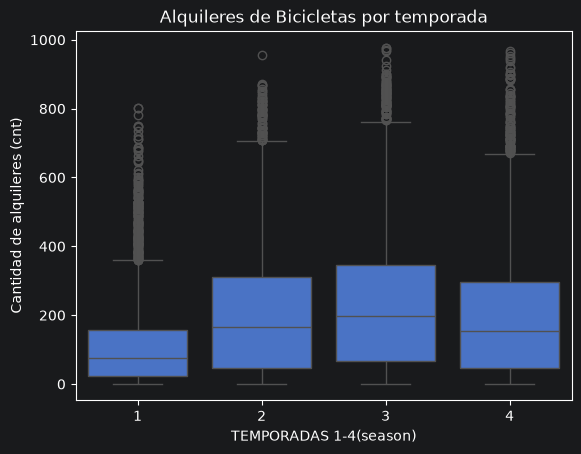

In [16]:
sns.boxplot(x='season',y='cnt',data=df)
plt.title("Alquileres de Bicicletas por temporada")
plt.xlabel("TEMPORADAS 1-4(season)")
plt.ylabel("Cantidad de alquileres (cnt)")

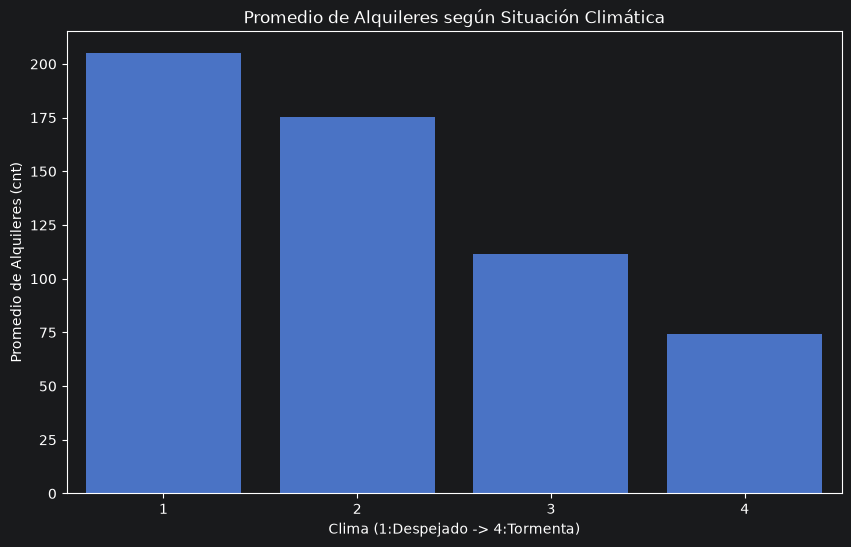

In [17]:
plt.figure(figsize=(10,6))
sns.barplot(data=df, x='weathersit', y='cnt', estimator=np.mean, errorbar=None)
plt.title("Promedio de Alquileres según Situación Climática")
plt.xlabel("Clima (1:Despejado -> 4:Tormenta)")
plt.ylabel("Promedio de Alquileres (cnt)")
plt.show()


In [18]:
#Esto sirve para dividir las demandas en alta, mediana, baja 

#cortes = df['cnt'].describe()
#print(cortes[['25%', '50%', '75%']])


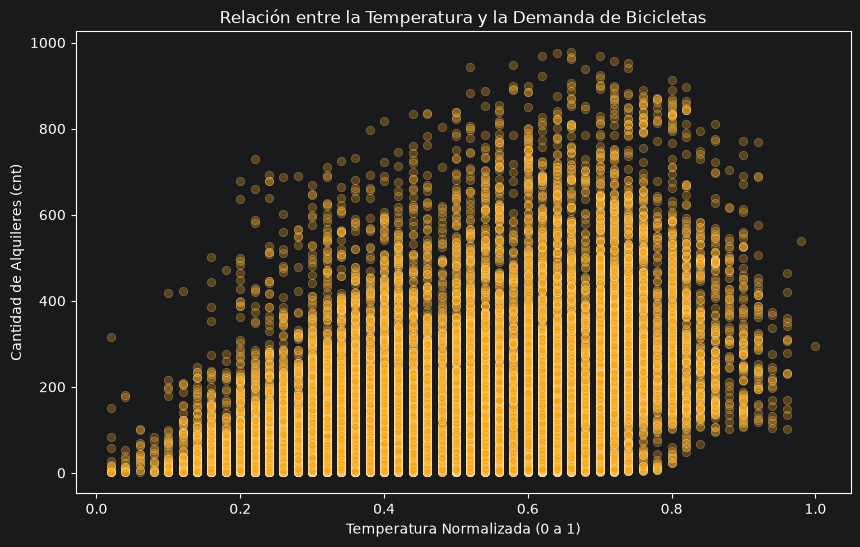

In [19]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='temp', y='cnt', alpha=0.3, color='orange')
plt.title("Relación entre la Temperatura y la Demanda de Bicicletas")
plt.xlabel("Temperatura Normalizada (0 a 1)")
plt.ylabel("Cantidad de Alquileres (cnt)")
plt.show()


# Reducción de variables

In [20]:
df = df.drop(['instant', 'dteday', 'yr','mnth', 'casual', 'registered'], axis=1)

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   season      17379 non-null  int64  
 1   hr          17379 non-null  int64  
 2   holiday     17379 non-null  int64  
 3   weekday     17379 non-null  int64  
 4   workingday  17379 non-null  int64  
 5   weathersit  17379 non-null  int64  
 6   temp        17379 non-null  float64
 7   atemp       17379 non-null  float64
 8   hum         17379 non-null  float64
 9   windspeed   17379 non-null  float64
 10  cnt         17379 non-null  int64  
dtypes: float64(4), int64(7)
memory usage: 1.5 MB
